# 07 · Suppliers in China: Phone Photos, Videos and a Scale. Learning the Owner's Acceptance Criteria per Product

**Juan Antonio Sainz Gálvez** · Applied AI & ML, Conestoga College · [Portfolio home](../README.md)

<a href="https://colab.research.google.com/github/antoniosg2025-stack/applied-ai-research-portfolio/blob/main/notebooks/07_suppliers_phone_inspection_weight.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

> **Main thesis question.** How can LLM agents learn, from an owner's approvals, rejections and corrections, a **decision profile** grounded in the owner's personality and situation (constraints and strengths: economic, skills, cognitive, family and business), so that they **minimize the gap between the agent's decision and the decision the owner would have made**, across different types of decisions, as the owner evolves, and when other users operate the system on the owner's behalf, **deferring to the owner** whenever that gap is likely to be large?
>
> **Error, in this portfolio, always means:** the agent decided differently from how the owner would have decided.

**This case:** I import from Chinese suppliers into Mexico and Canada. An agent finds suppliers; samples are ordered on Alibaba with shipping insurance and sent to a person I trust, who inspects them **with her phone** (photos and videos) and sends them to me. If the sample passes, the full order goes to her, she inspects again, consolidates shipments from several suppliers in a forwarding warehouse, and they ship. The risk I know from ten years with my own inspection offices in Shenzhen and Hong Kong: a supplier quietly swaps a component for a lighter or cheaper one. I am adding a **scale** to the inspection. The question: can an agent learn when I would accept a lot, product by product, from photos, videos and weight?


In [1]:
# Visual style used across the portfolio
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import FancyBboxPatch

PALETTE = {"navy": "#1B2A41", "teal": "#0F7C80", "gold": "#E0A526",
           "coral": "#D9534F", "sky": "#5BA4CF", "grey": "#8A94A6", "light": "#F4F6F9"}
POLICY_COLORS = [PALETTE["grey"], PALETTE["sky"], PALETTE["gold"], PALETTE["teal"], PALETTE["coral"]]

mpl.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": "#D5DAE1", "axes.grid": True, "grid.color": "#E9ECF1", "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 14, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 11, "axes.labelcolor": "#3A4556", "xtick.color": "#5A6576", "ytick.color": "#5A6576",
    "legend.frameon": False, "font.family": "DejaVu Sans",
    "axes.prop_cycle": mpl.cycler(color=POLICY_COLORS),
})


def box(ax, xy, w, h, text, color, fontsize=10, text_color="white"):
    """Rounded box for infographics."""
    ax.add_patch(FancyBboxPatch(xy, w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=color, ec="none"))
    if text:
        ax.text(xy[0] + w / 2, xy[1] + h / 2, text, ha="center", va="center",
                color=text_color, fontsize=fontsize, fontweight="bold")


def arrow(ax, start, end, color="#8A94A6"):
    ax.annotate("", xy=end, xytext=start,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2, shrinkA=4, shrinkB=4))


def thesis_card(case, profile, decision, signal):
    """The same infographic opens every notebook: owner profile -> agent decision model -> act or ask."""
    fig, ax = plt.subplots(figsize=(12, 4.6)); ax.set_xlim(0, 12); ax.set_ylim(0, 4.6); ax.axis("off")
    box(ax, (0.1, 0.35), 4.0, 3.5, "", PALETTE["navy"])
    ax.text(2.1, 3.45, "OWNER PROFILE", ha="center", color="white", fontsize=11, fontweight="bold")
    for i, item in enumerate(profile[:5]):
        ax.text(0.3, 2.9 - i * 0.5, "• " + item, color="white", fontsize=9, va="center")
    box(ax, (4.55, 1.55), 3.2, 1.6, "Agent learns how\nthe owner decides:\n" + decision, PALETTE["teal"], fontsize=10.5)
    box(ax, (4.55, 0.35), 3.2, 0.9, "learns from:\n" + signal, PALETTE["sky"], fontsize=9.5)
    box(ax, (8.3, 2.5), 3.5, 1.1, "Likely the same decision\nas the owner  ->  ACT", PALETTE["gold"], fontsize=10.5)
    box(ax, (8.3, 0.75), 3.5, 1.1, "Likely a different decision\n->  ASK THE OWNER", PALETTE["coral"], fontsize=10.5)
    arrow(ax, (4.1, 2.35), (4.5, 2.35)); arrow(ax, (7.8, 2.6), (8.25, 3.0)); arrow(ax, (7.8, 2.1), (8.25, 1.3))
    ax.set_title("Case: " + case, pad=4)
    plt.show()


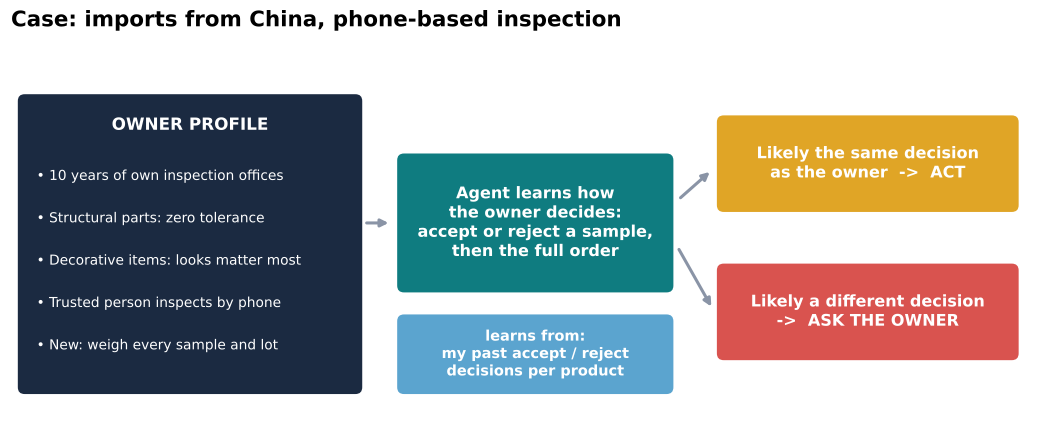

In [2]:
thesis_card("imports from China, phone-based inspection",
            ["10 years of own inspection offices", "Structural parts: zero tolerance",
             "Decorative items: looks matter most", "Trusted person inspects by phone",
             "New: weigh every sample and lot"],
            "accept or reject a sample,\nthen the full order",
            "my past accept / reject\ndecisions per product")

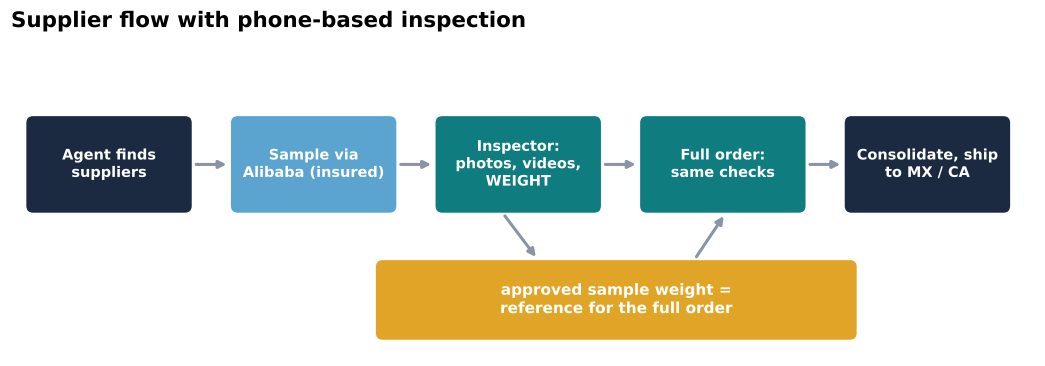

In [3]:
# Infographic: the real flow, and where each check happens
fig, ax = plt.subplots(figsize=(12, 3.8)); ax.set_xlim(0, 12); ax.set_ylim(0, 3.8); ax.axis("off")
steps = [("Agent finds\nsuppliers", PALETTE["navy"]), ("Sample via\nAlibaba (insured)", PALETTE["sky"]),
         ("Inspector:\nphotos, videos,\nWEIGHT", PALETTE["teal"]), ("Full order:\nsame checks", PALETTE["teal"]),
         ("Consolidate, ship\nto MX / CA", PALETTE["navy"])]
for i, (t, c) in enumerate(steps):
    box(ax, (0.2 + i * 2.4, 1.7), 1.9, 1.1, t, c, fontsize=9.5)
    if i < len(steps) - 1: arrow(ax, (2.1 + i * 2.4, 2.25), (2.6 + i * 2.4, 2.25))
box(ax, (4.3, 0.2), 5.6, 0.9, "approved sample weight =\nreference for the full order", PALETTE["gold"], fontsize=10)
arrow(ax, (5.75, 1.7), (6.2, 1.1)); arrow(ax, (8.0, 1.1), (8.4, 1.7))
ax.set_title("Supplier flow with phone-based inspection", pad=4)
plt.show()

## 1. Literature

| Research line | Key result | What it gives this case |
|---|---|---|
| Quality fade [1] | After winning an importer's trust with good early orders, contract manufacturers may quietly substitute materials and steps, too gradually for the buyer to notice | Substitutions are the risk; the first good sample is not proof |
| Acceptance sampling and switching rules [2, 3] | Inspection intensity switches between normal, tightened and reduced based on recent history | A hand-written trust rule; it uses the same tolerance for every product |
| Statistical quality control and check-weighing [4] | Control limits on a measured variable detect shifts in a process | Weight is a cheap, continuous measurement that photos do not give |
| Supplier evaluation [5] | Quality is the most used supplier-selection criterion | Supports measuring each supplier lot by lot |
| Learning to defer [6] | Decide when to pass the case to the expert | Uncertain lots go to the owner |

**Gap.** Acceptance sampling fixes one tolerance per standard. The owner's real criterion differs by product (a structural part versus a decorative item), and photos rarely show a swapped material. The thesis asks the agent to learn the owner's tolerance per product and to use the measurement that actually reveals substitution.


## 2. Experiment: 12 months of samples and full orders

Nine suppliers in three product types: **structural metal parts**, **electronic components** and **decorative items**. Each supplier sends a sample and then a monthly full order. Three suppliers start swapping a component after month 4 (a lighter metal or a cheaper part), which changes the weight by 4–8% but is visible in a phone photo only 15% of the time. Ordinary visual defects are caught by photos and videos 70% of the time. The scale is precise to about ±1%.

**The owner's real criterion (hidden from the agent)**: structural parts are rejected for any substitution or visible defect; electronics are rejected for substitution or defects; decorative items are rejected only for visible defects (a lighter decorative item is acceptable if it looks right).

Three inspection policies:

1. **Photos and videos only** (today).
2. **Photos + weight with one fixed tolerance** (reject any lot more than 3% off the reference weight, every product).
3. **Photos + weight + the owner's tolerance per product**, learned from his past accept/reject decisions, with the **approved sample's weight as the reference**; lots the model is unsure about go to the owner.

**Error** = the agent's decision differs from the owner's.


In [4]:
import numpy as np
import pandas as pd
from sklearn.linear_model import LogisticRegression

TYPES = ["structural metal", "electronics", "decorative"]
SUPPLIERS = [(f"S{i+1}", TYPES[i % 3]) for i in range(9)]
FADERS = {"S1", "S5", "S9"}          # one of each type starts swapping a component after month 4

def lot(rng, sup, ptype, month):
    swapped = sup in FADERS and month >= 4
    defect = rng.random() < 0.06
    true_shift = -rng.uniform(0.04, 0.08) if swapped else 0.0
    measured = true_shift + rng.normal(0, 0.01)                       # scale noise about 1%
    photo_sees_swap = swapped and rng.random() < 0.15
    photo_sees_defect = defect and rng.random() < 0.70
    return dict(supplier=sup, ptype=ptype, month=month, swapped=swapped, defect=defect, weight_dev=measured,
                photo_flag=int(photo_sees_swap or photo_sees_defect))

def owner_decision(l):
    if l["ptype"] == "decorative": return int(not l["defect"])        # looks are what matter
    return int(not (l["defect"] or l["swapped"]))

def history(seed, months=12):
    """Past lots the owner decided himself (training data for the agent)."""
    rng = np.random.default_rng(seed); rows = []
    for m in range(months):
        for sup, pt in SUPPLIERS:
            l = lot(rng, sup, pt, m + 6) if rng.random() < 0.5 else lot(rng, sup, pt, 0)
            l["owner_accepts"] = owner_decision(l); rows.append(l)
    return pd.DataFrame(rows)

past = history(1)
models = {pt: LogisticRegression(C=5).fit(np.c_[100 * g.weight_dev.abs(), g.photo_flag], g.owner_accepts) for pt, g in past.groupby("ptype")}
print("Owner decisions available for learning:", len(past))

Owner decisions available for learning: 108


In [5]:
def run(policy, seed=0, months=12, ask_band=(0.2, 0.8)):
    rng = np.random.default_rng(seed); rows = []
    for m in range(months):
        for sup, pt in SUPPLIERS:
            l = lot(rng, sup, pt, m); truth = owner_decision(l); asked = 0
            if policy == "photos and videos only":
                accept = int(not l["photo_flag"])
            elif policy == "photos + weight, one tolerance":
                accept = int(not l["photo_flag"] and abs(l["weight_dev"]) < 0.03)
            else:
                p = models[pt].predict_proba([[100 * abs(l["weight_dev"]), l["photo_flag"]]])[0, 1]
                if ask_band[0] < p < ask_band[1]:
                    accept, asked = truth, 1                          # sent to the owner with photos, video and weight
                else:
                    accept = int(p >= 0.5)
            rows.append(dict(policy=policy, month=m, ptype=pt, swapped=l["swapped"], truth=truth, accept=accept, asked=asked))
    return pd.DataFrame(rows)

POL = ["photos and videos only", "photos + weight, one tolerance", "photos + weight + owner's tolerance per product"]
runs = pd.concat([run(p, seed=s) for p in POL for s in range(20)])
summary = runs.groupby("policy").apply(lambda g: pd.Series({
    "decisions_different_from_owner_pct": 100 * (g.accept != g.truth).mean(),
    "lots_owner_would_reject_but_shipped": ((g.accept == 1) & (g.truth == 0)).sum() / 20,
    "good_lots_rejected": ((g.accept == 0) & (g.truth == 1)).sum() / 20,
    "swapped_parts_shipped_structural_electronics": ((g.accept == 1) & g.swapped & (g.ptype != "decorative")).sum() / 20,
    "lots_sent_to_owner": g.asked.sum() / 20}), include_groups=False).loc[POL].round(1)
summary

,decisions_different_from_owner_pct,lots_owner_would_reject_but_shipped,good_lots_rejected,swapped_parts_shipped_structural_electronics,lots_sent_to_owner
policy,,,,,
photos and videos only,14.6,14.6,1.1,13.2,0.0
"photos + weight, one tolerance",8.4,1.6,7.4,0.2,0.0
photos + weight + owner's tolerance per product,2.5,2.8,0.0,0.1,6.4


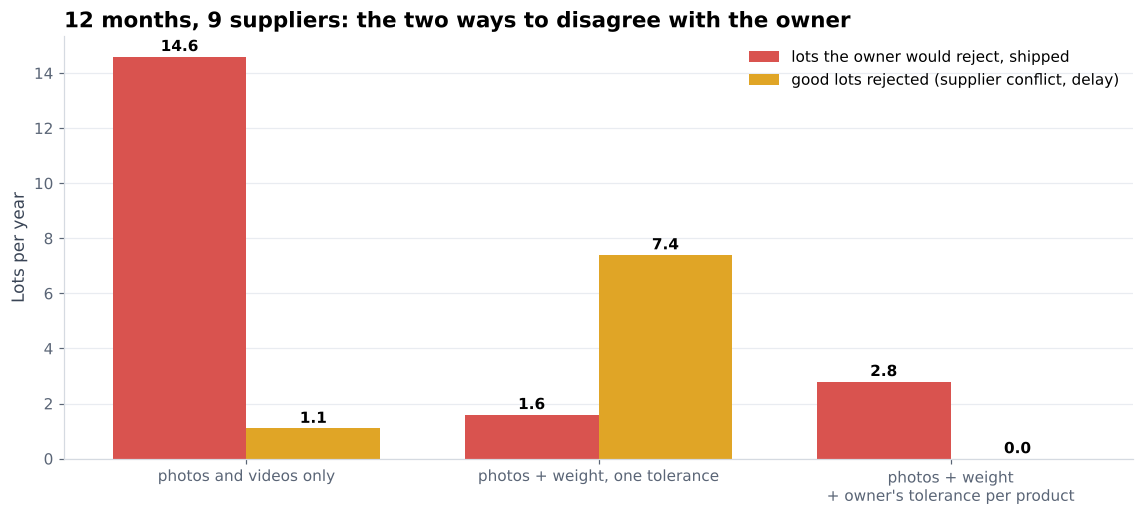

In [6]:
fig, ax = plt.subplots(figsize=(10.5, 4.8))
x = np.arange(len(POL)); w = 0.38
b1 = ax.bar(x - w / 2, summary.lots_owner_would_reject_but_shipped, w, color=PALETTE["coral"], label="lots the owner would reject, shipped")
b2 = ax.bar(x + w / 2, summary.good_lots_rejected, w, color=PALETTE["gold"], label="good lots rejected (supplier conflict, delay)")
for bars in (b1, b2):
    for b in bars: ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.2, f"{b.get_height():.1f}", ha="center", fontweight="bold")
ax.set_xticks(x); ax.set_xticklabels([p.replace(" + owner's", "\n+ owner's") for p in POL]); ax.grid(axis="x", visible=False)
ax.set_title("12 months, 9 suppliers: the two ways to disagree with the owner")
ax.set_ylabel("Lots per year"); ax.legend()
plt.tight_layout(); plt.show()

In [7]:
# How fast is a swap noticed? Month of the first rejection of a swapping supplier's lot (structural and electronics)
def first_catch(policy, seed):
    r = run(policy, seed=seed); out = []
    for pt in ["structural metal", "electronics"]:
        g = r[(r.ptype == pt) & r.swapped]
        caught = g[g.accept == 0]
        out.append((caught.month.min() - 4) if len(caught) else 8.0)   # never caught in 12 months: counted as 8
    return np.mean(out)
delay = pd.Series({p: np.nanmean([first_catch(p, s) for s in range(20)]) for p in POL}).round(1)
print("Months from the start of the swap to its first rejection:"); print(delay.to_string())

Months from the start of the swap to its first rejection:
photos and videos only                             4.2
photos + weight, one tolerance                     0.0
photos + weight + owner's tolerance per product    0.0


## 3. Findings

> **Key finding 1.** Phone photos and videos catch visible defects but almost never a swapped material: with photos alone, about **13 lots a year** with a swapped structural or electronic component ship, and a swap goes unnoticed for about 4 months on average. The scale catches it on the **first lot**, because weight is the measurement the swap actually changes.
>
> **Key finding 2.** One fixed weight tolerance for every product catches the swaps but rejects about **7 good lots a year** that the owner would have accepted (lighter decorative items that look right): it disagrees with the owner in the other direction, creating supplier conflicts and delays.
>
> **Key finding 3.** Learning the owner's tolerance **per product type** from his past decisions, with the approved sample's weight as the reference, cuts disagreement with the owner from about 15% of lots (photos only) and 8% (one tolerance) to about **2.5%**, rejects no good lots, and sends about 6 ambiguous lots a year to the owner. The remaining errors are defects that neither photos nor weight reveal. The owner's profile here is a set of tolerances that depend on what the product is for, learned from decisions he has already made.

**Limitations:** simulated suppliers and swaps; the 15% chance that a photo reveals a swap and the ±1% scale precision are assumptions to be measured with the real inspector.

## 4. Thesis questions

1. Can an LLM agent read the inspector's photos and videos together with the weight and explain to the owner, in one message, why a lot looks different from the approved sample?
2. How should the owner's tolerance transfer to a new product type he has never inspected?
3. When the inspector (a specifier) disagrees with the agent, how does the agent keep the owner's criterion and pass her judgment to the owner (notebook 01)?

## References

1. Midler, P. (2009). *Poorly Made in China: An Insider's Account of the Tactics Behind China's Production Game.* Wiley.
2. ISO 2859-1:1999. *Sampling procedures for inspection by attributes — Part 1.* International Organization for Standardization.
3. Dodge, H. F. (1955). *Skip-lot sampling plan.* Industrial Quality Control, 11(5), 3–5.
4. Montgomery, D. C. (2019). *Introduction to Statistical Quality Control* (8th ed.). Wiley.
5. Ho, W., Xu, X., & Dey, P. K. (2010). *Multi-criteria decision making approaches for supplier evaluation and selection: A literature review.* European Journal of Operational Research, 202(1), 16–24.
6. Mozannar, H., & Sontag, D. (2020). *Consistent Estimators for Learning to Defer to an Expert.* ICML 2020.
